# AdaTSK: from a first fit to the setting of the article

This notebook builds, one step at a time, the classifier of

> G. Xue, Q. Chang, J. Wang, K. Zhang and N. R. Pal, "An adaptive neuro-fuzzy system with
> integrated feature selection and rule extraction for high-dimensional classification
> problems", *IEEE Transactions on Fuzzy Systems*, vol. 31, no. 7, 2023.

on Wine, one of the datasets of the article. AdaTSK computes the firing strength of a
rule with Ada-softmin, a smooth minimum whose sharpness adapts to the membership degrees.
The notebook is a short version of the script `examples/reproductions/adatsk_2022.py`,
which runs three datasets with ten folds repeated five times; here one repetition on one
dataset runs in about a minute.

1. settings and reproducibility;
2. the data;
3. the rule base of the article;
4. the training: what the learning rate and the number of iterations change;
5. what the fitted model looks like;
6. ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import ADATSKClassifier

In [2]:
SEED = 0
FOLDS = 10
THREADS = 1

# Table III of the article, Wine: mean test accuracy in percent.
ARTICLE = 98.7

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Wine has 178 samples of three cultivars, described by 13 chemical measurements.

In [3]:
wine = load_wine()
features, labels = wine.data.astype(np.float32), wine.target

print(f"{features.shape[0]} samples, {features.shape[1]} features, {labels.max() + 1} classes")
print(f"samples per class: {np.bincount(labels).tolist()}")

178 samples, 13 features, 3 classes
samples per class: [59, 71, 48]


The first of ten folds is followed in detail. The inputs are scaled to [0, 1] with the
range of the training part; the article does not state the scale it uses.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))

scaler = MinMaxScaler().fit(features[train])
x_train, x_test = scaler.transform(features[train]), scaler.transform(features[test])
y_train, y_test = labels[train], labels[test]

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 160 samples, test: 18 samples


## 3. The rule base of the article

Three fuzzy sets per feature, with centres evenly placed between the minimum and the
maximum of the training part, and three rules: rule *i* takes the *i*-th set of every
feature. The membership function is $e^{-(x - m)^2}$, which has no spread to train. These
are the defaults of `ADATSKClassifier`.

A model trained for a single iteration shows the rule base as it starts:

rules: 3


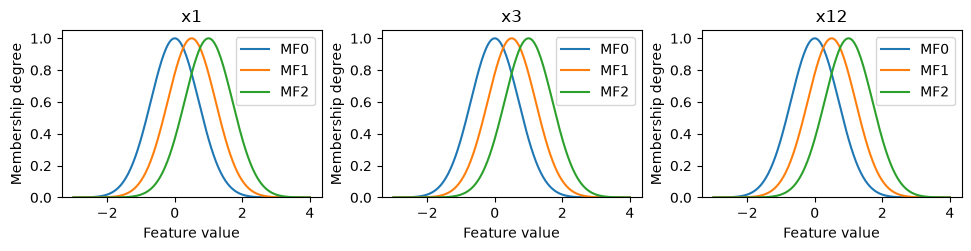

In [5]:
initial = ADATSKClassifier(epochs=1, consequent_batch_norm=False, random_state=SEED).fit(x_train, y_train)

print(f"rules: {initial.model_.n_rules}")
initial.plot_memberships(max_features=3)
plt.show()

On inputs in [0, 1] the three sets of a feature overlap widely: a value at one end still
has a degree of $e^{-1} = 0.37$ in the set at the other end.

## 4. The training

The article trains by gradient descent on the whole training set, with the consequents
starting at zero and no normalization of the consequent inputs. It does not state the
learning rate nor the number of iterations, so three settings are compared on this fold.

In [6]:
settings = {
    "0.01, 100 iterations": dict(learning_rate=0.01, epochs=100),
    "0.05, 300 iterations": dict(learning_rate=0.05, epochs=300),
    "0.05, 1000 iterations": dict(learning_rate=0.05, epochs=1000),
}
models = {}
for label, arguments in settings.items():
    models[label] = ADATSKClassifier(consequent_batch_norm=False, random_state=SEED, **arguments)
    models[label].fit(x_train, y_train)
    print(
        f"{label:22s} training {100 * models[label].score(x_train, y_train):5.1f}%  "
        f"test {100 * models[label].score(x_test, y_test):5.1f}%"
    )

0.01, 100 iterations   training  69.4%  test  72.2%


0.05, 300 iterations   training  95.6%  test 100.0%


0.05, 1000 iterations  training  98.1%  test 100.0%


Plain gradient descent is slow from consequents at zero. The loss of the three runs:

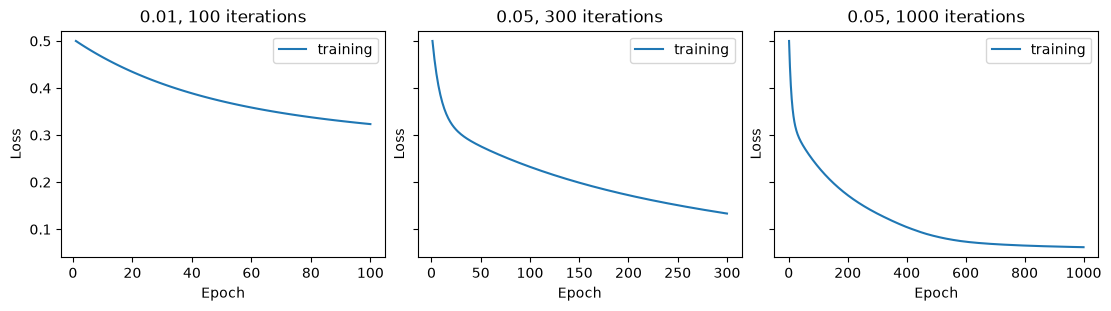

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True, layout="constrained")
for ax, (label, fitted) in zip(axes, models.items()):
    fitted.plot_history(ax=ax)
    ax.set_title(label)
plt.show()

The reproduction uses a learning rate of 0.05 and 1000 iterations.

The default of the estimator is another choice: `learning_rate="auto"` takes a step that
is safe for any number of features, and the consequent inputs are normalized, which
makes the training faster. It is meant to work without tuning, in low and in high
dimension:

In [8]:
default = ADATSKClassifier(random_state=SEED).fit(x_train, y_train)

print(f"learning rate chosen: {default.learning_rate_:.4f}, epochs: {default.epochs}")
print(f"training {100 * default.score(x_train, y_train):.1f}%, test {100 * default.score(x_test, y_test):.1f}%")

learning rate chosen: 0.0714, epochs: 300
training 100.0%, test 100.0%


## 5. What the fitted model looks like

The model of the article's setting, with 1000 iterations. Its confusion matrix on the 18
test samples, and the margin of each decision:

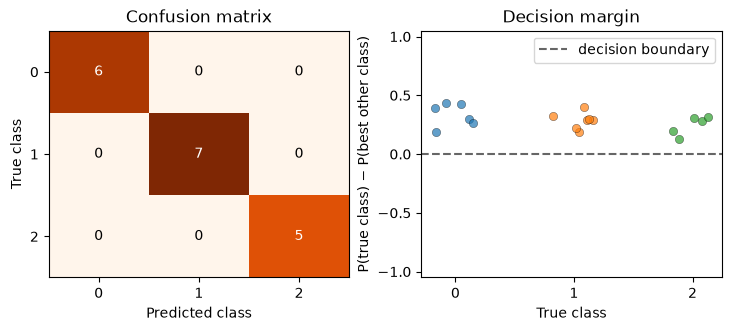

In [9]:
model = models["0.05, 1000 iterations"]
model.plot_diagnostics(x_test, y_test)
plt.show()

How the three rules share the samples of each class:

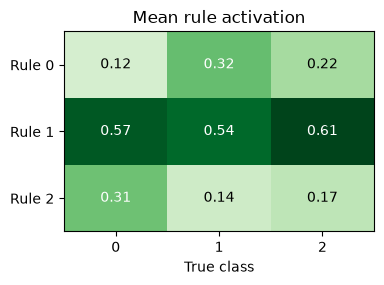

In [10]:
fig, ax = plt.subplots(figsize=(4, 2.6))
model.plot_rule_activation(x_test, y_test, ax=ax)
plt.show()

The rules as sentences, with the three features that weigh most in each consequent:

In [11]:
print(model.rules_as_text(top_features=3))

Rule 0: IF x10 is low AND x12 is low AND x13 is low AND ... (10 more)
        THEN 0: -0.32 - 0.31 * x4 + 0.27 * x13 - 0.18 * x8 + ...
             1: 0.61 + 0.45 * x11 + 0.40 * x12 + 0.31 * x4 + ...
             2: 0.20 + 0.38 * x10 - 0.31 * x12 + 0.26 * x2 + ...
Rule 1: IF x10 is medium AND x12 is medium AND x13 is medium AND ... (10 more)
        THEN 0: -0.20 + 0.60 * x13 - 0.42 * x4 + 0.35 * x1 + ...
             1: 0.47 - 0.54 * x13 - 0.52 * x10 + 0.49 * x11 + ...
             2: 0.29 + 0.60 * x10 - 0.52 * x12 - 0.44 * x7 + ...
Rule 2: IF x10 is high AND x12 is high AND x13 is high AND ... (10 more)
        THEN 0: 0.18 + 0.40 * x13 + 0.34 * x1 + 0.32 * x12 + ...
             1: -0.00 - 0.36 * x1 - 0.33 * x13 - 0.28 * x10 + ...
             2: 0.07 - 0.25 * x12 + 0.22 * x10 - 0.21 * x7 + ...


A summary of the model and of its training, in one call:

In [12]:
print(model.summary())

ADATSKClassifier
  task               classification, 3 classes
  features           13 seen in fit, 13 used by the model
  rules              3 (rule base: coco)
  fuzzy sets         3 per feature, ADATSKGaussianMF
  firing strength    AdaSoftminRuleLayer
  defuzzifier        SumBasedDefuzzifier
  consequents        ClassificationConsequentLayer
  parameters         165 trainable (39 antecedent, 126 consequent)
Training
  batch size         full batch
  epochs             1000 epochs, learning rate 0.05, training loss 0.5000 -> 0.0618, training accuracy 0.9812


How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [13]:
print(model.explain(x_test[0]))

Prediction: 0
Output, the sum of the contributions of the 3 rules: 0: +1.17, 1: -0.21, 2: +0.04
Rule 1, weight 0.55: contributes 0: +0.59, 1: +0.00, 2: +0.10
    IF x10 is medium AND x12 is medium AND x13 is medium AND ... (10 more)
Rule 2, weight 0.36: contributes 0: +0.60, 1: -0.33, 2: -0.08
    IF x10 is high AND x12 is high AND x13 is high AND ... (10 more)
Rule 0, weight 0.09: contributes 0: -0.02, 1: +0.11, 2: +0.02
    IF x10 is low AND x12 is low AND x13 is low AND ... (10 more)


How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [14]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.89, median 0.95
test part:     min 0.92, median 0.95


## 6. Ten folds, next to the article

The ten folds with the setting of the reproduction, and with the defaults of the
estimator.

In [15]:
results = {"article setting": [], "defaults": []}

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = MinMaxScaler().fit(features[train])
    a_train, a_test = scaler.transform(features[train]), scaler.transform(features[test])

    fitted = ADATSKClassifier(learning_rate=0.05, epochs=1000, consequent_batch_norm=False, random_state=SEED)
    results["article setting"].append(100 * fitted.fit(a_train, labels[train]).score(a_test, labels[test]))

    fitted = ADATSKClassifier(random_state=SEED)
    results["defaults"].append(100 * fitted.fit(a_train, labels[train]).score(a_test, labels[test]))

print(f"article: {ARTICLE:.2f}")
for label, scores in results.items():
    print(f"{label:16s} {np.mean(scores):6.2f} +- {np.std(scores):.2f}")

article: 98.70
article setting   96.05 +- 3.59
defaults          99.44 +- 1.67


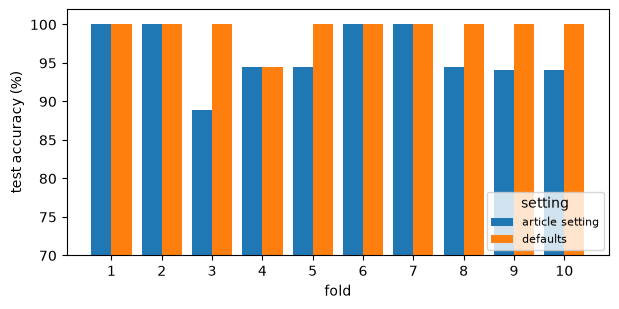

In [16]:
LOWER, LEGEND = 70, "setting"

fold_means = {label: np.asarray(scores) for label, scores in results.items()}

fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.8 / len(fold_means)
for position, (label, scores) in enumerate(fold_means.items()):
    ax.bar(np.arange(FOLDS) + (position - (len(fold_means) - 1) / 2) * width, scores, width=width, label=str(label))
ax.set_xticks(np.arange(FOLDS), [str(fold + 1) for fold in range(FOLDS)])
ax.set_xlabel("fold")
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(LOWER, 102)
ax.legend(loc="lower right", fontsize=8, title=LEGEND)
plt.show()

With 18 test samples per fold, one sample is 5.6 points. The script repeats the ten folds
five times and also runs Iris and Wdbc; over the five repetitions Wine gives 96.52,
against 98.7 in the article.

## Environment

In [17]:
highfis.show_versions()

highfis       : 0.33.0
python        : 3.11.15
platform      : Linux-7.0.0-38-generic-x86_64-with-glibc2.43
torch         : 2.14.1+cu130
numpy         : 2.4.6
scikit-learn  : 1.9.1
default dtype : torch.float32
threads       : 1
cpu           : Intel(R) Core(TM) Ultra 7 258V
